# Project traffic

Please fill in the names of the team members.

<div class="alert alert-block alert-danger">

<b>Team: XX</b>
- Max Mustermann 471108
- XX
- XX

<b>Result:</b>

| Task   |    1  |    2  |    3  |    4  |    5  |    6  |    7  |    8  |    9  |  Sum  |
|--------|-------|-------|-------|-------|-------|-------|-------|-------|-------|-------|
| Points | ?/0.2 | ?/0.2 | ?/0.2 | ?/0.2 | ?/0.3 | ?/0.2 | ?/0.2 | ?/0.3 | ?/0.2 | ?/2.0 |


</div>

## Packages

Please set up a virtual environment:

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
```

<div class="alert alert-block alert-danger">

<b>Important: Do not import other packages or libraries!</b>

</div>

### Python

In [49]:
from platform import python_version
print('python version = '+ python_version())

python version = 3.14.7


### Display images and videos

In [50]:
from IPython.display import HTML, Image, display

### NumPy

In [51]:
import numpy as np
print('numpy version = '+ np.__version__)

numpy version = 2.5.3


### Matplotlib

In [52]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
print('matplotlib version = '+ matplotlib.__version__)

matplotlib version = 3.11.2


## 1 Modelling
Everybody knows the situation: you are driving on the motorway, the traffic suddenly slows down, you have to stop, and a few minutes later the traffic flows freely again.
There was no accident, no construction site and no lane reduction.
Such a traffic jam is called a *phantom traffic jam* or a *jam out of nowhere*.

In 2008 a group of Japanese physicists around Yuki Sugiyama showed in a remarkable experiment that no bottleneck is needed for a traffic jam to form.
They placed $22$ cars on a circular track with a circumference of $230$ m.
The drivers were asked to drive steadily at about $30$ km/h and to keep a safe distance from the car in front.
At the beginning the traffic flowed freely.
But small fluctuations of the distances between the cars grew, until a cluster of cars was forced to stop completely for a moment.
This cluster travelled backwards through the traffic like a wave at roughly $20$ km/h, which is about the same speed as stop-and-go waves on real motorways.
Cars at the front of the cluster could escape at up to $40$ km/h, while other cars joined the cluster at its back.
The experiment can be seen in the following video: [https://www.youtube.com/watch?v=Rryu85BtALM](https://www.youtube.com/watch?v=Rryu85BtALM).

In this project we want to reproduce the experiment with a computer simulation.
We use a so-called *microscopic* traffic model, where every car is described individually by its position and its velocity.
In contrast, *macroscopic* models describe the traffic like a fluid by density and mean velocity.
More precisely, we use a *car-following model*:
every driver adjusts the velocity of their car depending on the distance to the car in front.
The interesting question is how such a simple local rule can lead to a collective phenomenon like a traffic jam that moves backwards.

A detailed simulation study of the ring road experiment, which served as inspiration for this project, can be found here: [https://www.k-dense.ai/blog/phantom-traffic-jam-ring-road-simulation](https://www.k-dense.ai/blog/phantom-traffic-jam-ring-road-simulation).

## 2 Numerical treatment
In this chapter we translate the ring road experiment into mathematics.
First we describe the state of the cars by their positions and velocities and derive the quantities that characterise the traffic: gaps, density and flow.
Then we discuss how the experiment starts, which gives us the initial values.
As we will see, the motion of the cars is described by a system of ordinary differential equations (ODEs).
Together with the initial values, we obtain an initial value problem, which we will solve numerically.

### 2.1 Ring road, position and velocity
We assign a unique index between $0$ and $N-1$ to each car.
Here $N$ denotes the number of cars.
All cars have the same length $\ell$.
The cars drive clockwise on a ring road with length $L$, as in the video of the experiment.
The position $x_n(t) \in [0,L)$ of car $n$ depends on time $t$ and is measured along the road at the rear bumper of the car.
The cars are numbered in driving direction, i.e. car $n+1$ drives directly in front of car $n$.
Car $n+1$ is called the *leader* of car $n$.
Because the road is a ring, the leader of the last car $N-1$ is the first car $0$.

The positions alone do not determine the motion of the cars, we also need to know how fast they drive.
Therefore, each car $n$ contributes two unknown functions of time: its position $x_n(t)$ and its velocity $v_n(t)$.
For $N$ cars we have $2N$ unknown functions.

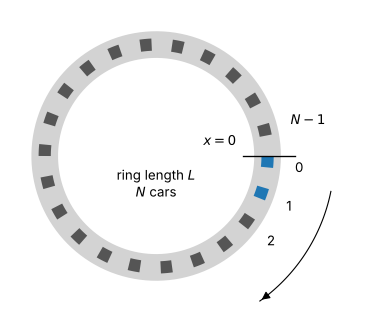

In [53]:
Image('traffic_ring_figure.png', width=366, height=312)

### 2.2 Gap and collision
The *gap* $s_n(t)$ of car $n$ is the free distance between its front bumper and the rear bumper of its leader:

$$
    s_n(t) = x_{n+1}(t) - x_n(t) - \ell, \quad n = 0, 1, \ldots, N-2,
    \qquad
    s_{N-1}(t) = x_{0}(t) + L - x_{N-1}(t) - \ell .
$$

Both cases can be written in a single formula using the modulo operation:

$$
    s_n(t) = \big( (x_{(n+1) \bmod N}(t) - x_n(t)) \bmod L \big) - \ell, \quad n = 0,1,\ldots,N-1.
$$

Since the gaps and the cars together cover the whole ring, the gaps always satisfy

$$
    \sum_{n=0}^{N-1} s_n(t) + N \ell = L .
$$

A negative gap would mean that two cars overlap, i.e. a collision.

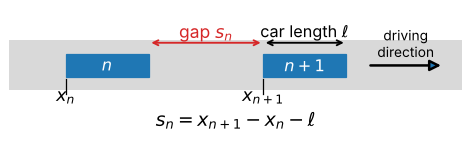

In [54]:
Image('traffic_gap_figure.png', width=471, height=150)

### 2.3 Start of the experiment
To compute the motion of the cars, we need the positions $x_n(0)$ and the velocities $v_n(0)$ of all cars at the start time $t=0$, i.e. $2N$ initial values.
There are several possibilities to start the experiment:

- **Start from rest, all cars at the same time:**
All cars stand still, $v_n(0) = 0$, and start driving at the same moment.
This is how a real experiment begins, but in practice drivers never start at exactly the same moment.
- **Start from rest, one car after the other:**
Each driver only starts when the car in front has started to move.
This is more realistic, but the different start times already create large differences between the gaps.
- **Start in motion:**
All cars are already driving with the same initial velocity, $v_n(0) = v_\text{init}$, and are distributed uniformly on the ring.
This corresponds to the phase of the Sugiyama experiment that was actually observed: the drivers first got rolling and settled at about $30$ km/h.
- **Start in motion with a perturbation:**
As before, but the cars are slightly displaced from their uniform positions, all cars by small random distances.
This models the small mistakes that every driver makes.

We use the last possibility.

The start-up phase is not part of what we want to investigate, and the small perturbation is the trigger for the instability.

### 2.4 Uniform flow
Traffic engineers describe traffic by two macroscopic quantities.
The *density* $\rho$ is the number of cars per length, usually given in vehicles per kilometre (veh/km).
The *flow* $q$ is the number of cars passing a fixed point per time, usually given in vehicles per hour (veh/h).
In the *uniform flow*, all cars are distributed uniformly on the ring road and drive with the same constant velocity $v$.
The distance between the rear bumpers of two successive cars is $L/N$, so all cars have the same gap

<a id="uniform_flow_gap"></a>

$$
    s^* = \frac{L}{N} - \ell .
    \tag{1}
$$

If car $0$ starts at $x_0(0) = 0$, the positions and velocities are

$$
    x_n(t) = \left( n \, \frac{L}{N} + v t \right) \bmod L, \qquad v_n(t) = v, \qquad n = 0, 1, \ldots, N-1 .
$$

The whole configuration moves around the ring without changing its shape, the gaps remain $s_n(t) = s^*$ for all times.
Density and flow of the uniform flow are $\rho = N/L$ and $q = \rho \, v$.

<div class="alert alert-block alert-warning">

<b>Example (Sugiyama experiment)</b>

In the experiment of Sugiyama et al. (2008), $N = 22$ cars drove on a single-lane circular track with a circumference of $L = 230$ m.
For the length of the cars we assume an average value of $\ell = 4.4$ m.
The drivers were asked to drive steadily at $v_\text{init} = 30$ km/h:

<a id="sugiyama"></a>

$$
    L = 230 \text{ m}, \qquad N = 22, \qquad \ell = 4.4 \text{ m}, \qquad v_\text{init} = 30 \text{ km/h}.
    \tag{2}
$$

</div>

<div class="alert alert-block alert-info">

### Task 1: Uniform flow in Sugiyama experiment <font color=red>(0.2 points)</font>
Suppose the cars of the Sugiyama experiment [(2)](#sugiyama) are distributed uniformly on the ring road and all of them drive with $v_\text{init} = 30$ km/h.
Calculate the distance between the rear bumpers of two successive cars, the gap $s^*$, the density $\rho$ and the flow $q$.
</div>

<div class="alert alert-block alert-success">

<b>Solution of Task 1</b>

<b>ToDo: put your text here!</b>

</div>

### 2.5 Optimal velocity model
In 1995 Bando, Hasebe, Nakayama, Shibata and Sugiyama proposed a very simple car-following model, the so-called *optimal velocity model* (OV model).
The basic idea is the following:
every driver has an *optimal velocity* $V(s)$ in mind, which only depends on the gap $s$ to the car in front.
With a small gap the driver wants to drive slowly, with a large gap the driver wants to drive fast.

For the optimal velocity function we use the typical S-shaped function:
<a id="velocity"></a>

$$
    V(s) = \frac{v_\text{max}}{2} \left( \tanh\left(\frac{s - s_c}{w}\right) + \tanh\left(\frac{s_c}{w}\right) \right) .
    \tag{3}
$$

It depends on three parameters: the velocity parameter $v_\text{max}$, the safety gap $s_c$, at which the function has its turning point, and the width $w$ of the transition from slow to fast driving.
We use the following values:
<a id="velocity_parameter"></a>

$$
    v_\text{max} = 12 \text{ m/s} \, (43.2 \text{ km/h}), \qquad s_c = 4.5 \text{ m}, \qquad w = 3 \text{ m} .
    \tag{4}
$$

The function has the following properties:

- For $s = 0$ the optimal velocity is $V(0) = 0$, i.e. a driver stops if the car touches the car in front.
- The function is strictly increasing, i.e. larger gaps lead to higher optimal velocities.
- For very large gaps the optimal velocity approaches the free-flow velocity

$$
    \lim_{s \to \infty} V(s) = \frac{v_\text{max}}{2}\left(1 + \tanh\left(\frac{s_c}{w}\right)\right) .
$$

- The steepest increase is at the turning point $s = s_c$.

### 2.6 Initial value problem
The driver does not adjust the velocity instantly, but accelerates or brakes proportionally to the difference between the optimal velocity $V(s_n)$ and the actual velocity $v_n$.
This leads to the following system of $2N$ ODEs:
<a id="initial_value_problem"></a>

$$
\begin{aligned}
    \frac{\mathrm{d} x_n}{\mathrm{d} t} &= v_n , \\[1ex]
    \frac{\mathrm{d} v_n}{\mathrm{d} t} &= a \, \big( V(s_n) - v_n \big) ,
\end{aligned}
\qquad n = 0, 1, \ldots, N-1.
\tag{5}
$$

The parameter $a > 0$ is called the *sensitivity* of the drivers.
Its inverse $\tau = 1/a$ has the unit of a time and can be interpreted as the reaction time or relaxation time of the drivers.
The larger the sensitivity $a$, the faster the drivers adapt their velocity.
We use $a = 2.5 \text{ s}^{-1}$, i.e. a reaction time of $\tau = 0.4$ s.

Together with the $2N$ initial values $x_n(0)$ and $v_n(0)$, the system [(5)](#initial_value_problem) is an initial value problem.
An important special solution of the model [(5)](#initial_value_problem) is the *uniform flow*:
all cars have the same gap $s^*$ and drive with the same velocity $v^*$.

<div class="alert alert-block alert-info">

### Task 2: Steady state of the OV model <font color=red>(0.2 points)</font>
Show that the uniform flow with gap $s^*$ and constant velocity $v^* = V(s^*)$ is a solution of the initial value problem [(5)](#initial_value_problem).
Calculate the velocity $v^*$ of the uniform flow for the Sugiyama experiment [(2)](#sugiyama).
</div>

<div class="alert alert-block alert-success">

<b>Solution of Task 2</b>

<b>ToDo: put your text here!</b>

</div>

### 2.7 Explicit Euler method
The initial value problem [(5)](#initial_value_problem) is a nonlinear system of ODEs, which cannot be solved analytically.
Therefore we solve it numerically.
The simplest method for this purpose is the *explicit Euler method*.

We divide the time interval $[0, T]$ into steps of length $\Delta t$ and compute approximations at the times $t^k = k \, \Delta t$.
We denote the approximations of position and velocity of car $n$ at time $t^k$ by $x_n^k$ and $v_n^k$.
The derivatives are replaced by forward difference quotients:

$$
    \frac{x_n^{k+1} - x_n^k}{\Delta t} = v_n^k,
    \qquad
    \frac{v_n^{k+1} - v_n^k}{\Delta t} = a \, \big( V(s_n^k) - v_n^k \big) .
$$

Solving for the new values gives the update formulas:
<a id="euler"></a>

$$
\begin{aligned}
    x_n^{k+1} &= \big( x_n^k + \Delta t \, v_n^k \big) \bmod L , \\[1ex]
    v_n^{k+1} &= v_n^k + \Delta t \, a \, \big( V(s_n^k) - v_n^k \big) .
\end{aligned}
\tag{6}
$$

The modulo operation keeps the positions in the interval $[0, L)$ when a car passes the point $x = 0$.
Starting from the initial values $x_n^0$ and $v_n^0$ we can compute all further values step by step.

The time step $\Delta t$ must not be chosen too large.
The Euler method assumes that the velocity and the acceleration of each car remain constant during a time step.
In reality they change continuously, so every step introduces a small error, and these errors accumulate over many steps.
The larger the time step, the larger the error.
If the time step is too large, the numerical solution can even become completely wrong, for example the cars may collide although this does not happen in the exact solution of the model.
On the other hand, a small time step requires many steps and therefore a long computing time:
to simulate $15$ minutes with $\Delta t = 0.01$ s, we already need $90\,000$ time steps.

The choice of the time step is therefore always a compromise between accuracy and computing time.
For the hand calculation in the following task we use a comparatively large time step of $\Delta t = 0.1$ s, so that the changes are visible after only a few steps.
We will discuss in chapter 5 Evaluation, how the results of the simulation depend on the time step and which time step is small enough.

<div class="alert alert-block alert-info">

### Task 3: Euler by hand <font color=red>(0.2 points)</font>
Consider the smallest possible ring road with only $N = 2$ cars.
To obtain the same density as in the Sugiyama experiment, the ring has the length $L = 2 \cdot 230 \, \text{m} / 22 = 20.909$ m.
The car length is $\ell = 4.4$ m, the sensitivity is $a = 2.5 \text{ s}^{-1}$ and the parameters of the velocity function are [(4)](#velocity_parameter).

Write down the initial value problem [(5)](#initial_value_problem) explicitly for the two cars, i.e. all four equations with both gaps expressed by the positions $x_0$ and $x_1$.

Car $0$ starts at $x_0(0) = 0.5$ m, car $1$ at $x_1(0) = L/2$, and both cars drive with $v_0(0) = v_1(0) = v_\text{init} = 30$ km/h.
Calculate two steps of the explicit Euler method [(6)](#euler) with $\Delta t = 0.1$ s.
Give the gaps, positions and velocities after each step.
Which car brakes, which car accelerates?
</div>

<div class="alert alert-block alert-success">

<b>Solution of Task 3</b>

<b>ToDo: put your text here!</b>

</div>

## 3 Implementation
Our goal is to implement the OV model and the explicit Euler method and to test them.
Every part of chapter 2 gets its own small function, all with the prefix `traffic`, so that the functions can be tested one by one and combined later.

All functions use the values of the Sugiyama experiment [(2)](#sugiyama) and of the velocity function [(4)](#velocity_parameter) as default values of their keyword arguments.
A call without arguments therefore reproduces the experiment, e.g.

```python
trafficUniformFlowGap()
```

At the same time we stay flexible: every parameter can be changed in the call, e.g. for a ring with only $12$ cars

```python
trafficUniformFlowGap(N=12)
```

We never use these values as fixed numbers inside a function.
All quantities are given in SI units (m, s, m/s).
We only convert to km/h for printing and plotting.

The simulation computes many time steps, but we only store some of them.
The stored results are handed over to the visualisation in chapter 4 as three NumPy arrays:
the times `t`, the positions `X` and the velocities `V` (see section 3.6).
Each stored time step becomes one frame of the animation.

### 3.1 Ring road, position and velocity
The state of all cars at a time $t$ is given by the $2N$ values $x_n(t)$ and $v_n(t)$.
We store them in two NumPy vectors of type `float` and length $N$:

- `x[n]` is the position $x_n$ of car $n$ in m, with $0 \le$ `x[n]` $< L$,
- `v[n]` is the velocity $v_n$ of car $n$ in m/s.

The index of the vector is the number of the car, so the leader of car `n` is car `n+1`, and the leader of car `N-1` is car `0`.
Vectors let us compute with all cars at once (e.g. `x + dt*v`) without a loop over the cars.
This is short and much faster than a Python loop.

### 3.2 Gap and collision
We also store the gaps in a vector `s`.
On the ring road every car has a leader, so there are exactly $N$ gaps and `s` has the same length as `x` and `v`.

The function `trafficGap()` implements the modulo formula from section 2.2.
`np.roll(x, -1)` shifts the vector by one position to the left, so its entry `n` is `x[(n+1) % N]`, the position of the leader.
The difference is taken `% L` to handle the leader of the last car, which has already passed the point $x = 0$.

In [55]:
def trafficGap(x, L=230, ell=4.4):
    s = (np.roll(x,-1) - x) % L - ell
    return s

After every time step we check whether a collision has happened, i.e. whether one of the gaps is not positive:

```python
np.any(s < np.finfo(s.dtype).eps*L)
```

`np.finfo(s.dtype).eps` is the machine epsilon of the data type of `s`, for `float64` about $2.2 \cdot 10^{-16}$.
`np.any()` returns `True` if the condition holds for at least one car.

Why don't we just test `s < 0`?
The gaps are computed in floating point arithmetic, so they contain rounding errors.
The positions are numbers up to $L = 230$ m, and every arithmetic operation with them has a relative error of about `eps`.
The absolute rounding error of a gap is therefore about `eps*L`, for the Sugiyama experiment about $5 \cdot 10^{-14}$ m.
If two cars touch, the exact gap is $0$, but the computed gap may be a tiny positive number of this size, and the test `s < 0` would miss the contact.
With the threshold `eps*L`, everything that is zero up to rounding errors counts as a collision.
This makes the result independent of how the rounding happens to go.
A real gap is many orders of magnitude larger than `eps*L`, so the threshold never raises a false alarm.

The collision must be detected immediately.
Because of the `% L` in `trafficGap()` a car that has driven through its leader would get a gap close to $L$ and the collision would be invisible.
With a small time step a car moves only a few centimetres per step.
The gap is therefore always negative for at least one step before this can happen.

### 3.3 Start of the experiment
We start in motion with a perturbation (section 2.3).
First the cars are placed uniformly on the ring, `np.linspace(0, L, N, endpoint=False)` gives the positions $n \, L/N$.
Then every car is shifted by its own random distance

$$
    x_n(0) = n \, \frac{L}{N} + \delta_n , \qquad \delta_n \in \left[ -\frac{p \, \ell}{2}, \, \frac{p \, \ell}{2} \right] ,
$$

where $\delta_n$ is drawn from a uniform distribution.
For this we use the random number generator of NumPy: `rng = np.random.default_rng(seed)` creates a generator,
and `rng.uniform(-p*ell/2, p*ell/2, N)` returns a vector with $N$ uniformly distributed random numbers at once, without a loop.
The parameter $p$ is the size of the perturbation relative to the car length.
With $p = 0.1$ each car is displaced by at most $\pm 0.05 \, \ell = \pm 0.22$ m, which is small compared to the gap $s^* = 6.05$ m.
The cars therefore do not collide at the start, but every gap is slightly different.
After the shift we apply `% L` again, because car $0$ can be moved to a negative position.
All cars start with the same velocity $v_\text{init}$.

The perturbation is random, so every run gives a slightly different result.
With the optional argument `seed` the random number generator can be initialised, so that a run can be repeated exactly.
With `seed=None` (the default) NumPy takes a fresh random state from the operating system, so every run is different.

In [56]:
def trafficInitialValues(L=230, N=22, ell=4.4, v_init=30.0/3.6, p=0.1, seed=None):
    rng = np.random.default_rng(seed)                 # seed=None: different perturbation in every run
    x0 = np.linspace(0, L, N, endpoint=False)         # uniform positions in m
    delta = rng.uniform(-p*ell/2, p*ell/2, N)         # random displacements in m
    x0 = (x0 + delta) % L                             # random perturbation of the positions
    v0 = v_init*np.ones_like(x0)                      # 30 km/h in m/s
    return x0, v0

### 3.4 Uniform flow

We implement the function `trafficUniformFlowGap()` according to the formula [(1)](#uniform_flow_gap) with the default parameters from the Sugiyama experiment [(2)](#sugiyama).

In [57]:
def trafficUniformFlowGap(L=230.0, N=22, ell=4.4):
    s_star = L/N - ell
    return s_star

### 3.5 Optimal velocity model
In the OV model the acceleration of a car depends only on its own velocity and on the optimal velocity $V(s_n)$ for its gap.
So the optimal velocity function [(3)](#velocity) is the only part of the model that describes the behaviour of the drivers.
We implement it as `trafficVelocity()`.
NumPy's `np.tanh()` works element by element, so the function can be called with a single gap or with the whole gap vector `s`.
It then returns the optimal velocities of all cars at once.

<div class="alert alert-block alert-info">

### Task 4: Velocity function <font color=red>(0.2 points)</font>
Implement the velocity function `trafficVelocity()` according to the formula [(3)](#velocity) with the default parameters [(4)](#velocity_parameter).
Plot the velocity $V(s)$ for gaps $0 \le s \le 30$ m .
Mark the free-flow velocity and the gap $s^*$ of the Sugiyama experiment from task 1 in the plot.
</div>

<div class="alert alert-block alert-success">

<b>Solution of Task 4</b>

Implementation of the velocity function:
</div>

In [58]:
def trafficVelocity(s, v_max=12.0, s_c=4.5, w=3.0):
    V = np.zeros_like(s)
    #
    # ToDo: put your code here!
    #
    return V

<div class="alert alert-block alert-success">

<b>Solution of Task 4</b>

Plot of the velocity function:
</div>

In [59]:
#
# ToDo: put your code here!
#

### 3.6 Explicit Euler method
The function `trafficEuler()` implements the update formulas [(6)](#euler).
It gets the initial values `x0`, `v0`, the parameters of the model, the time step `dt` and the end time `T`, and computes `nsteps = T/dt` time steps.
In each step all cars are updated at once with vector operations.
Both new values $x_n^{k+1}$ and $v_n^{k+1}$ must be computed from the old values $x_n^k$, $v_n^k$ and $s_n^k$.
Therefore the gaps are computed once at the beginning of the step, before `x` is changed.

**Storing the results.**
With `dt = 0.01` s and `T = 900` s we compute $90\,000$ steps.
Storing every step is not necessary: an animation shows only a few frames per second, and the cars move very little in $0.01$ s.
Therefore only every `nout`-th step is stored, together with the initial values.
With the default `nout = 50` this is every $0.5$ s, i.e. $1\,801$ stored states for $15$ minutes.
The function returns three NumPy arrays:

- `t` with shape `(M,)`: the stored times in s,
- `X` with shape `(M, N)`: row `X[k]` holds the positions of all cars at time `t[k]`,
- `V` with shape `(M, N)`: row `V[k]` holds the velocities of all cars at time `t[k]`.

$M$ is the number of stored states.
Column `X[:, n]` is the trajectory of car `n`.
During the simulation the results are collected in Python lists, because `append()` is cheap.
They are converted to arrays at the end.

**Collision.**
Before each step the gaps are checked as described in section 3.2.
If a collision is detected, the simulation stops with a message and returns the results computed so far.

<div class="alert alert-block alert-info">

### Task 5: Explicit Euler method <font color=red>(0.3 points)</font>
Implement the explicit Euler method [(6)](#euler) with collision detection in the function `trafficEuler()`.
Store every `nout`-th time step in the arrays `t`, `X` and `V`.
Test the function with the two cars of task 3: compute two time steps with $\Delta t = 0.1$ s and compare the gaps, positions and velocities with your hand calculation.
</div>

<div class="alert alert-block alert-success">

<b>Solution of Task 5</b>

Implementation of the explicit Euler method:
</div>

In [60]:
def trafficEuler(x0, v0, L=230, ell=4.4, a=2.5, dt=0.01, T=900, nout=50, v_max=12, s_c=4.5, w=3.0):
    nsteps = int(round(T/dt))
    x = x0.copy()
    v = v0.copy()
    t = [0.0]
    X = [x.copy()]
    V = [v.copy()]
    #
    # ToDo: put your code here!
    #
    return np.array(t), np.array(X), np.array(V)

<div class="alert alert-block alert-success">

<b>Solution of Task 5</b>

Test with the two cars of task 3:
</div>

In [61]:
#
# ToDo: put your code here!
#

## 4 Visualization
The function `trafficEuler()` returns the positions and velocities of all cars as long lists of numbers.
Such numbers hardly show *where* the cars are slow and how a jam moves.
An animation of the ring road makes this visible at a glance.

This chapter has two parts.
In section 4.1 we turn the results `t`, `X` and `V` of `trafficEuler()` into an animation of the ring road.
An animation is good for getting a feeling for the motion, but it shows only one moment at a time.
In section 4.2 we therefore draw the whole simulation in a single picture, the space-time diagram, and use it to estimate how fast the jam moves.

The finished animation of a simulation over $6$ minutes should look like this:

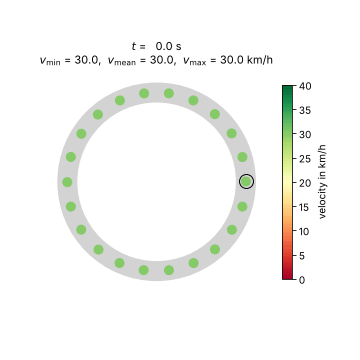

In [62]:
Image('traffic_animation.gif', width=400, height=400)

### 4.1 Animation
The positions $x_n$ are arc lengths on the ring road.
For a visualisation we convert them into the angle $\varphi_n = -2\pi \, x_n / L$ and plot the cars on a circle with radius $R = L/(2\pi)$:

<a id="ring_coordinates"></a>

$$
    \big( R \cos \varphi_n, \, R \sin \varphi_n \big) .
    \tag{7}
$$

The point $x = 0$ lies on the right of the ring ($\varphi = 0$).
The minus sign makes the angle decrease with increasing position, so the cars drive clockwise, as in the experiment.

The colour of each car shows its velocity, from red (standing) to green (fast).
Car $0$ is marked with a black circle, so that we can follow it while it passes through the jam again and again.
The current time and the minimal, mean and maximal velocity are shown in the title.

We use `FuncAnimation` from Matplotlib.
An animation consists of many *frames*, and it would be slow to draw every frame from scratch.
Therefore everything that does not change (the road, the axes, the colour bar) is drawn only once.
For the cars and the title we create graphic objects (*artists*) once, and in every frame we only update their data.
This leads to three functions:

| Function | Called | Job |
|---|---|---|
| `trafficDrawInit()` | once | draw the road, create the artists for cars, tracer and title |
| `trafficDrawFrame()` | once per frame | move the artists to the positions of one stored time step |
| `trafficAnimation()` | once | create the figure and combine both functions with `FuncAnimation` |

The first function is given, the other two are your tasks.
All three functions get the data they need as arguments and do not use global variables.
So they work for every simulation, for example with another number of cars $N$ or another road length $L$.

#### 4.1.1 Drawing the ring road
The road is a wide light gray circle with radius $R = L/(2\pi)$, drawn with `plt.Circle()` and `ax.add_patch()`.
The axes are only a drawing area here: we switch off frame and ticks, use the same scale in $x$ and $y$ direction (otherwise the circle becomes an ellipse) and leave some space around the road.

The cars are drawn with `ax.scatter()`, which returns a `PathCollection`.
Its colours are taken from the colour map `'RdYlGn'` with the fixed range $0$ to `v_range` km/h, so that a colour means the same velocity in every frame.
The tracer for car $0$ is a single unfilled black circle created with `ax.plot()`, the title is created with `ax.set_title()`.
At this point the artists do not contain any data yet; they are filled in by `trafficDrawFrame()`.

The function `trafficDrawInit(ax, L=230, v_range=40.0)` is given.
It draws the ring road of length $L$ into the axes `ax`, adds a colour bar for the velocity in km/h and returns the three artists:
the scatter plot `cars` for the cars, the line `tracer` for the marker of car $0$, and the text `title`.

The argument `v_range` is the upper limit of the colour scale in km/h: a standing car is red, a car with `v_range` or faster is green.
The range is fixed and does not adapt to the data, so that a colour means the same velocity in every frame of the animation and in the space-time diagram of section 4.2.
The default $40$ km/h is a little above the highest velocity of about $38$ km/h that occurs in the simulation, so the whole colour range is used.

In [63]:
def trafficDrawInit(ax, L=230, v_range=40.0):
    R = L/(2*np.pi)                                   # radius of the ring road in m
    ax.set_frame_on(False)
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
    ax.set_xlim(-1.25*R, 1.25*R)
    ax.set_ylim(-1.25*R, 1.25*R)
    ax.add_patch(plt.Circle((0, 0), R, fill=False, color='lightgray', linewidth=20, zorder=0))
    cars = ax.scatter([], [], c=[], cmap='RdYlGn', vmin=0, vmax=v_range, s=80, zorder=2)
    tracer, = ax.plot([], [], 'o', markersize=14, markerfacecolor='none', markeredgecolor='k', zorder=3)
    title = ax.set_title('', fontsize=11)
    ax.figure.colorbar(cars, ax=ax, shrink=0.7, label='velocity in km/h')
    return cars, tracer, title

The empty ring road of the Sugiyama experiment:

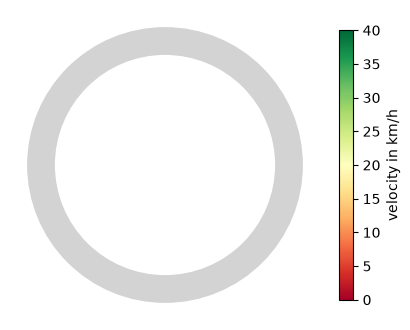

In [64]:
fig, ax = plt.subplots(figsize=(5,5))
cars, tracer, title = trafficDrawInit(ax)
plt.show()

#### 4.1.2 Drawing a frame
A frame shows the stored time step `k`, i.e. the positions `X[k]` and velocities `V[k]` at time `t[k]`.
The positions are converted with [(7)](#ring_coordinates) into $x$ and $y$ coordinates.
Then only the data of the existing artists are replaced:

- `cars.set_offsets(xy)` sets the coordinates of the cars, `xy` is an array of shape `(N, 2)`,
- `cars.set_array(v)` sets the values that are converted into colours, here the velocities in km/h,
- `tracer.set_data([x], [y])` moves the marker to car $0$,
- `title.set_text(...)` writes the time and the minimal, mean and maximal velocity.

Note the units: the simulation works in m/s, the colour bar and the title in km/h.

<div class="alert alert-block alert-info">

### Task 6: Draw a frame <font color=red>(0.2 points)</font>
Implement the function `trafficDrawFrame(k, t, X, V, cars, tracer, title, L=230)`, which updates the artists from `trafficDrawInit()` to the stored time step `k`.
The function returns the tuple `(cars, tracer, title)` of the changed artists.
Test the function by simulating the Sugiyama experiment for $T = 180$ s and drawing the first and the last stored time step side by side.
</div>

<div class="alert alert-block alert-success">

<b>Solution of Task 6</b>

Implementation of a frame:
</div>

In [65]:
def trafficDrawFrame(k, t, X, V, cars, tracer, title, L=230):
    #
    # ToDo: put your code here!
    #
    return cars, tracer, title

<div class="alert alert-block alert-success">

<b>Solution of Task 6</b>

Test with the first and the last stored time step of a simulation of the Sugiyama experiment:
</div>

In [66]:
#
# ToDo: put your code here!
#

#### 4.1.3 Animation
`FuncAnimation(fig, func, frames, fargs, interval)` calls the function `func` once for every element `k` of `frames` as `func(k, *fargs)` and records the figure after each call.
We pass `trafficDrawFrame` as `func` and the remaining arguments `(t, X, V, cars, tracer, title, L)` as the tuple `fargs`.
`interval` is the time between two frames in milliseconds.

We do not need to show every stored time step.
With `nout = 50` and `dt = 0.01` s a time step is stored every $0.5$ s.
If we only use every `step`-th stored time step with `step = 4` and `interval = 100` ms, one second of the animation shows $20$ s of the simulation.
This is fast enough to see the jam travel backwards.
To keep the notebook small, the figure is created with a low resolution of `dpi=72`, since every frame is stored as an image.

`to_jshtml()` converts the animation into an HTML player with buttons, which we show with `display(HTML(...))`.
Matplotlib also shows the figure itself as a still image when the cell ends; `plt.close(fig)` prevents that.
With `save()` the animation can be written to a GIF file, which can be watched without Jupyter.

<div class="alert alert-block alert-info">

### Task 7: Animation <font color=red>(0.2 points)</font>
Implement the function `trafficAnimation(t, X, V, L=230, step=4, interval=100, filename=None)`, which creates a figure, draws the ring road with `trafficDrawInit()` and returns a `FuncAnimation` that calls `trafficDrawFrame()` for every `step`-th stored time step.
If a file name is given, the animation is also saved as a GIF file.
Simulate the Sugiyama experiment for $T = 360$ s and show the animation.
Compare it with the animation `traffic_animation.gif` at the beginning of this chapter.
Since the initial perturbation is random, your jam will appear at another place, but it should look similar.
</div>

<div class="alert alert-block alert-success">

<b>Solution of Task 7</b>

Implementation of the animation:
</div>

In [67]:
def trafficAnimation(t, X, V, L=230, step=4, interval=100, filename=None):
    animation = None
    #
    # ToDo: put your code here!
    #
    return animation

<div class="alert alert-block alert-success">

<b>Solution of Task 7</b>

Animation of the Sugiyama experiment:
</div>

In [68]:
#
# ToDo: put your code here!
#

### 4.2 Moving jam
A very common way to show the results of a traffic simulation is the *space-time diagram*, also called trajectory diagram.
The time $t$ runs along the horizontal axis and the position $x$ along the vertical axis.
For each stored time step, the position of every car is plotted as a dot, coloured by its velocity with the same colour map as in the animation.
Each car leaves a line through the diagram.
When a car reaches the end of the ring at $x = L$, its line continues at $x = 0$.
In contrast to the animation, the space-time diagram shows the whole history of the traffic in a single picture.

A simulation over $15$ minutes is too long for one diagram, the lines of the cars would merge.
Therefore we only plot a time window $t_0 \le t \le t_1$.

`ax.scatter(T, X, c=V)` needs one time value for every dot, i.e. arrays of the same shape for times, positions and velocities.
The positions `X` and the velocities `V` have the shape `(M, N)`, the times `t` only the shape `(M,)`.
We therefore repeat the time vector once for every car, e.g. with `np.repeat(t[:,None], N, axis=1)`, which gives an array `T` of shape `(M, N)` with `T[k, n] = t[k]`.
A Boolean mask `(T >= t0) & (T <= t1)` then selects the dots inside the time window from all three arrays at once.

**Velocity of the jam.**
In the experiment the jam travelled backwards through the traffic at roughly $20$ km/h.
In the space-time diagram the jam is a red stripe, and its slope $\Delta x / \Delta t$ is the velocity of the jam.
A stripe from top left to bottom right has a negative slope, i.e. the jam moves backwards.
When the stripe reaches $x = 0$, it continues at $x = L$, so the stripe appears several times in a long time window.
The simplest estimate is therefore: read off the time $\Delta t$ the jam needs to travel once around the ring, i.e. from $x = L$ down to $x = 0$.
Then the velocity of the jam is about $-L/\Delta t$.

<div class="alert alert-block alert-info">

### Task 8: Space-time diagram <font color=red>(0.3 points)</font>
Implement the function `trafficSpaceTimeDiagram(ax, t, X, V, t0, t1, L=230, v_range=40.0)`, which draws the space-time diagram for the time window $t_0 \le t \le t_1$ into the axes `ax`.
Colour the dots by the velocity in km/h with the colour map `'RdYlGn'` in the range $0$ to `v_range`, label both axes and show the time window in the title.
The function returns the scatter plot, so that a colour bar can be added.

Simulate the Sugiyama experiment for $T = 900$ s and draw two space-time diagrams side by side with a common colour bar:
one for $0 \le t \le 300$ s, when the jam forms, and one for $600 \le t \le 700$ s, when the jam is fully developed.
Describe what you see.
Your diagrams should look similar to the following figure.
Since the initial perturbation is random, your jam will appear at another place.

<img src="traffic_space_time_figure.png" width="900">

Estimate the velocity of the jam in km/h from the right diagram and compare it with the experiment.
</div>

<div class="alert alert-block alert-success">

<b>Solution of Task 8</b>

Implementation of the space-time diagram:
</div>

In [69]:
def trafficSpaceTimeDiagram(ax, t, X, V, t0, t1, L=230, v_range=40.0):
    sc = None
    #
    # ToDo: put your code here!
    #
    return sc

<div class="alert alert-block alert-success">

<b>Solution of Task 8</b>

Test with the Sugiyama experiment:
</div>

In [70]:
#
# ToDo: put your code here!
#

<div class="alert alert-block alert-success">

<b>Solution of Task 8</b>

<b>ToDo: put your text here!</b>

</div>

## 5 Evaluation
Based on the animation and the space-time diagram, we get the impression that our modelling and simulation deliver reliable results.
However, when we take a closer look, we still see problems.
When evaluating our simulations, two different aspects play a role: verification and validation.
Verification and validation are not the same thing, although they are often confused.

### 5.1 Verification
Verification checks that the specifications are correctly implemented.
It gives an answer to the question:

__Are we implementing the simulation right?__

All results so far were computed with the explicit Euler method and $\Delta t = 0.01$ s.
We have to make sure that they describe the model and not the errors of the numerical method.
Task 5 already checked the implementation against the hand calculation of task 3.
Now we check the choice of the time step.

The explicit Euler method is a method of first order, i.e. the error is proportional to $\Delta t$.
Halving the time step therefore halves the error, but doubles the computing time.
We simulate the same initial values with different time steps and compare the minimum and maximum velocity of the cars for $t \geq 600$ s, when the jam is fully developed, and the minimum gap during the whole simulation.
To keep the number of stored states the same for all time steps, we store one state per second, i.e. `nout = 1/dt`.
If the cars collide, the collision detection from section 3.2 stops the simulation early.

<div class="alert alert-block alert-info">

### Task 9: Choice of the time step <font color=red>(0.2 points)</font>
Simulate the Sugiyama experiment for $T = 900$ s with the same initial values and the time steps $\Delta t = 0.2, 0.1, 0.05, 0.02, 0.01, 0.005$ s.
For each time step print whether a collision occurred, otherwise the minimum and maximum velocity for $t \geq 600$ s in km/h, and the minimum gap during the whole simulation.
How do the results depend on the time step?
Is $\Delta t = 0.01$ s small enough?
</div>

<div class="alert alert-block alert-success">

<b>Solution of Task 9</b>

Simulations with different time steps:
</div>

In [71]:
#
# ToDo: put your code here!
#

<div class="alert alert-block alert-success">

<b>Solution of Task 9</b>

<b>ToDo: put your text here!</b>

</div>

### 5.2 Validation
Validation checks that the simulation fulfils the needs and goals of the stakeholders.
It gives an answer to the question:

__Are we implementing the right simulation?__

To answer it, we compare the simulation with reality, i.e. with the observations of the Sugiyama experiment:

$$
\begin{array}{l|c|c}
 \text{observation} & \text{Sugiyama experiment (2008)} & \text{simulation} \\
\hline
 \text{number of jams} & 1 & 1 \\
 \text{velocity of the jam} & \text{roughly } 20 \text{ km/h backwards} & \text{your estimate from task 8} \\
 \text{velocity of cars leaving the jam} & \text{up to } 40 \text{ km/h} & 38 \text{ km/h} \\
 \text{velocity inside the jam} & \text{cars stop completely for a moment} & \text{cars crawl at about } 1 \text{ km/h} \\
\end{array}
$$

The simple OV model with only four parameters reproduces the experiment remarkably well, qualitatively and quantitatively.
No bottleneck and no accident is needed for the jam.
Only inside the jam there is a difference: in the simulation the cars do not stop completely, but crawl slowly.

**The random start does not matter.**
The initial perturbation is random, so every run starts differently.
Nevertheless the final state is always the same, as the following simulations with different seeds show.
The random perturbation only decides when and where the jam forms, but not how it looks.
The jam is a property of the model and the density, not of the initial disturbance.

In [72]:
for seed in [0, 815, 4711]:
    x0, v0 = trafficInitialValues(seed=seed)
    t, X, V = trafficEuler(x0, v0, T=900)
    if t[-1] < 900:
        print('trafficEuler() is not implemented yet or the simulation stopped early.')
        break
    mask = t >= 600
    print('seed = %4d:  v_min = %4.2f km/h,  v_max = %5.2f km/h,  cars slower than 10 km/h at the end: %d'
          % (seed, V[mask].min()*3.6, V[mask].max()*3.6, np.sum(V[-1]*3.6 < 10)))

trafficEuler() is not implemented yet or the simulation stopped early.


**Why does the jam form?**
The uniform flow is a solution of the model (task 2), but this does not mean that we observe it.
A pencil standing on its tip is also an equilibrium, but the smallest disturbance makes it fall over.
The important question is: what happens if one driver makes a small mistake?

Suppose a driver comes a little too close to the car in front.
The gap is smaller than $s^*$, so the optimal velocity is lower and the driver brakes.
But the driver does not react instantly, the velocity adapts only with the reaction time $\tau = 1/a = 0.4$ s.
When the driver finally drives slowly enough, the gap to the car behind has already shrunk.
The driver behind therefore has to brake a little later and a little harder, the next driver even harder, and so on.
Each driver overreacts a little bit, so the disturbance is amplified from car to car and travels backwards – a traffic jam has formed.

Two numbers decide whether a small disturbance grows or dies out.
The derivative $V'(s^*)$ of the velocity function describes how strongly the drivers *want* to react to a change of the gap.
The sensitivity $a$ describes how *fast* they are able to react.
A linear stability analysis (Bando et al. 1995) shows that the uniform flow is unstable, if

$$
    V'(s^*) > \frac{a}{2} .
$$

With $\tanh'(s) = 1 - \tanh^2(s)$ the derivative of the velocity function [(3)](#velocity) is

$$
    V'(s) = \frac{v_\text{max}}{2 w} \left( 1 - \tanh^2\left(\frac{s - s_c}{w}\right) \right) ,
$$

and for the Sugiyama experiment

$$
    V'(s^*) = 2 \, \text{s}^{-1} \, \left( 1 - 0.4763^2 \right) = 1.546 \, \text{s}^{-1} > 1.25 \, \text{s}^{-1} = \frac{a}{2} .
$$

The uniform flow is unstable, so the jam must form, exactly as in the simulation and in the experiment.
The drivers would need a sensitivity of at least $a_c = 2 V'(s^*) = 3.09 \, \text{s}^{-1}$, i.e. a reaction time shorter than $\tau_c = 1/a_c = 0.32$ s instead of $0.4$ s, to prevent the jam.
The density matters as well: $V'(s)$ is largest at the turning point $s = s_c = 4.5$ m.
The gap $s^* = 6.05$ m of the experiment is close to it, so the drivers react strongly to small changes of the gap.
With much larger gaps (low density) or much smaller gaps (very high density) $V'(s^*)$ is small and the uniform flow is stable.

**Limits of the model.**
If we compare our model with reality in more detail, we discover further differences.
In the OV model the drivers only look at the gap, not at the velocity of the car in front, and they do not anticipate what happens further ahead.
All drivers behave exactly the same, while real drivers have different temperaments.
We concentrated only on the pure motion of the cars and disregarded physical quantities such as mass, engine power and friction, which limit acceleration and braking.
The OV model does not even guarantee that the cars never collide if a car approaches much too fast.
More realistic models, like the *Intelligent Driver Model* (IDM), take some of these effects into account.

## 6 Embedding
A simulation is only useful if it describes reality and if we can learn something from it for practical use.
The Sugiyama experiment and our simulation show that a phantom traffic jam does not need a bottleneck: it is a collective effect of many drivers who each overreact a little bit.
This insight has several practical consequences.

**Attentive drivers and safe distances.**
In section 5.2 we saw that the jam disappears if the drivers react faster than $\tau_c = 0.32$ s, or if the gaps are larger, so that $V'(s^*)$ is smaller.
The practical advice is: keep a large distance, look further ahead, and avoid hard braking.
A driver who keeps a larger gap acts as a buffer and absorbs the fluctuations of the car in front instead of passing them on.

**Driver assistance and automated vehicles.**
Adaptive cruise control (ACC) adjusts the velocity automatically to the car in front.
If it is designed well, it reacts faster and more smoothly than a human driver and damps disturbances instead of amplifying them.
Stern et al. (2018) repeated the ring road experiment with more than $20$ cars.
Stop-and-go waves appeared as in the Sugiyama experiment, and they could be dampened by controlling the velocity of a single autonomous vehicle.
This suggests that a small fraction of automated vehicles can smooth the traffic long before most vehicles are automated, and it even reduces the fuel consumption of all cars.
Our simulation is exactly the kind of tool that is used to design and test such controllers before they are tried on a real road.

**Traffic control on motorways.**
The fundamental diagram of traffic flow shows that the flow first increases with the density and then decreases again.
Close to the maximum flow, where many motorways operate in the rush hour, the uniform flow becomes unstable, just like in the Sugiyama experiment.
Variable speed limits on motorway gantries and ramp metering at motorway entrances try to keep the traffic below this critical density and to harmonise the velocities.
The following video explains the phenomenon of the jam out of nowhere and shows how the maximum speed on German motorways (Autobahn) is adapted to the traffic by variable speed limits in order to avoid traffic jams:
[https://www.youtube.com/watch?v=iM1vKmLUR3U](https://www.youtube.com/watch?v=iM1vKmLUR3U).
Then fewer jams form and the flow is higher, because a jam reduces the flow considerably: cars in the jam crawl at about $1$ km/h instead of $30$ km/h.

**Beyond the ring road.**
Real roads have several lanes, ramps, bottlenecks and different vehicles, and drivers change lanes.
For traffic planning, microscopic models like the OV model or the IDM are combined with real road networks and traffic data in large simulation programs.
The effort of our simulation grows only linearly with the number of cars, so computing power is not the main problem; the challenges are good models and good data.

## Literature
 - [https://www.k-dense.ai/blog/phantom-traffic-jam-ring-road-simulation](https://www.k-dense.ai/blog/phantom-traffic-jam-ring-road-simulation)
 - Y. Sugiyama et al.: Traffic jams without bottlenecks – experimental evidence for the physical mechanism of the formation of a jam. New Journal of Physics 10 (2008) 033001. [https://doi.org/10.1088/1367-2630/10/3/033001](https://doi.org/10.1088/1367-2630/10/3/033001)
 - M. Bando et al.: Dynamical model of traffic congestion and numerical simulation. Physical Review E 51 (1995) 1035. [https://doi.org/10.1103/PhysRevE.51.1035](https://doi.org/10.1103/PhysRevE.51.1035)
 - [https://en.wikipedia.org/wiki/Traffic_wave](https://en.wikipedia.org/wiki/Traffic_wave)
 - [https://en.wikipedia.org/wiki/Fundamental_diagram_of_traffic_flow](https://en.wikipedia.org/wiki/Fundamental_diagram_of_traffic_flow)
 - [https://en.wikipedia.org/wiki/Euler_method](https://en.wikipedia.org/wiki/Euler_method)
 - [https://en.wikipedia.org/wiki/Intelligent_driver_model](https://en.wikipedia.org/wiki/Intelligent_driver_model)
 - R. E. Stern et al.: Dissipation of stop-and-go waves via control of autonomous vehicles: Field experiments. Transportation Research Part C 89 (2018) 205–221. [https://doi.org/10.1016/j.trc.2018.02.005](https://doi.org/10.1016/j.trc.2018.02.005)
 - [https://en.wikipedia.org/wiki/Adaptive_cruise_control](https://en.wikipedia.org/wiki/Adaptive_cruise_control)